In [46]:
import numpy as np
import random
random.seed(42)
np.random.seed(42)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import re
from nltk.corpus import stopwords
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import MaxAbsScaler

from imblearn.over_sampling import SMOTE
from sklearn.metrics import f1_score

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification
from torch.optim import AdamW
from transformers import get_scheduler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import CountVectorizer

import shap
from lime.lime_text import LimeTextExplainer

!pip install textstat -q

from textblob import TextBlob
import textstat
import spacy
from scipy.sparse import hstack, csr_matrix

from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix
import seaborn as sns

from sklearn.metrics import f1_score, recall_score
from scipy.sparse import hstack, csr_matrix

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.calibration import calibration_curve
from sklearn.utils import resample
from sklearn.metrics import roc_curve

In [47]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

df = pd.read_csv('/kaggle/input/datasets/shivamb/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv')

print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst 3 rows:")
df.head(3)

Shape: (17880, 18)

Column names:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

First 3 rows:


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, con...","Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and cu...",Experience with content management systems a major plus (any blogging counts!)Familiar with the ...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Produ...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer service? Slick typing...,"What we expect from you:Your key responsibility will be to communicate with the client, 90 Secon...",What you will get from usThrough being part of the 90 Seconds team you will gain:experience work...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions that meet the needs of companies across the Private ...,"Our client, located in Houston, is actively seeking an experienced Commissioning Machinery Assis...",Implement pre-commissioning and commissioning procedures for rotary equipment.Execute all activi...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


# EDA

### Class Distribution & Missing Values

Exploratory data analysis begins with understanding the target variable distribution and data completeness. Given the nature of fraud detection, class imbalance is expected and will directly influence modeling decisions.

In [48]:
print("Fraudulent distribution:")
print(df['fraudulent'].value_counts())
print("\nPercentage:")
print(df['fraudulent'].value_counts(normalize=True).round(3) * 100)

print("\nMissing values per column:")
print(df.isnull().sum().sort_values(ascending=False))


Fraudulent distribution:
fraudulent
0    17014
1      866
Name: count, dtype: int64

Percentage:
fraudulent
0    95.2
1     4.8
Name: proportion, dtype: float64

Missing values per column:
salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
title                      0
job_id                     0
telecommuting              0
has_questions              0
has_company_logo           0
fraudulent                 0
dtype: int64


The dataset is highly imbalanced, with only 4.8% of postings labeled as fraudulent (866 out of 17,880). Multiple techniques will be explored and compared to determine the most effective approach. Additionally, several columns exhibit significant missingness - most notably salary_range (84%), department (65%), and required_education (45%), which may itself serve as a signal, as fraudulent postings tend to omit structured information.


### Text & Visual Analysis

Visual analysis of text length and categorical distributions provides intuition about structural differences between real and fraudulent postings, patterns that will later inform feature engineering decisions.

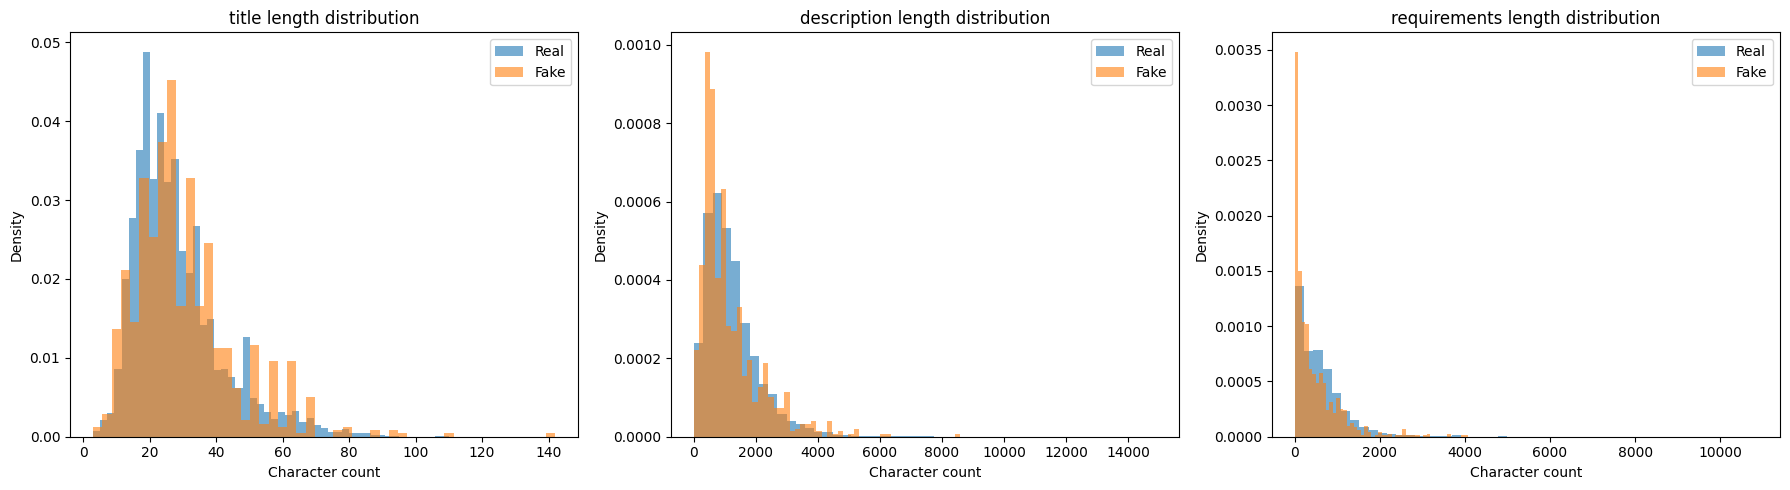

In [49]:
# Text length analysis
text_cols = ['title', 'description', 'requirements']

for col in text_cols:
    df[col + '_len'] = df[col].fillna('').apply(len)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(text_cols):
    for label, group in df.groupby('fraudulent'):
        axes[i].hist(group[col + '_len'], bins=50, alpha=0.6, 
                     label='Fake' if label == 1 else 'Real', density=True)
    axes[i].set_title(f'{col} length distribution')
    axes[i].set_xlabel('Character count')
    axes[i].set_ylabel('Density')
    axes[i].legend()

plt.tight_layout()
plt.show()


Text length distributions reveal structural differences between real and fraudulent postings. 
1. All three fields are right-skewed, with most postings concentrated at shorter lengths.
2. Fake postings tend to have slightly longer titles, possibly reflecting clickbait-style language designed to attract attention.
3. In contrast, fake descriptions and requirements are noticeably shorter — fraudulent postings invest less effort in providing substantive content, which may reflect either the absence of a real role or a deliberate strategy to avoid scrutiny.

Text length is therefore a promising feature for the modeling phase.

### Word Clouds: Real vs Fake Postings

Word clouds visualize the most frequent terms in real and fraudulent job descriptions, offering a first look at the linguistic patterns that distinguish the two classes.

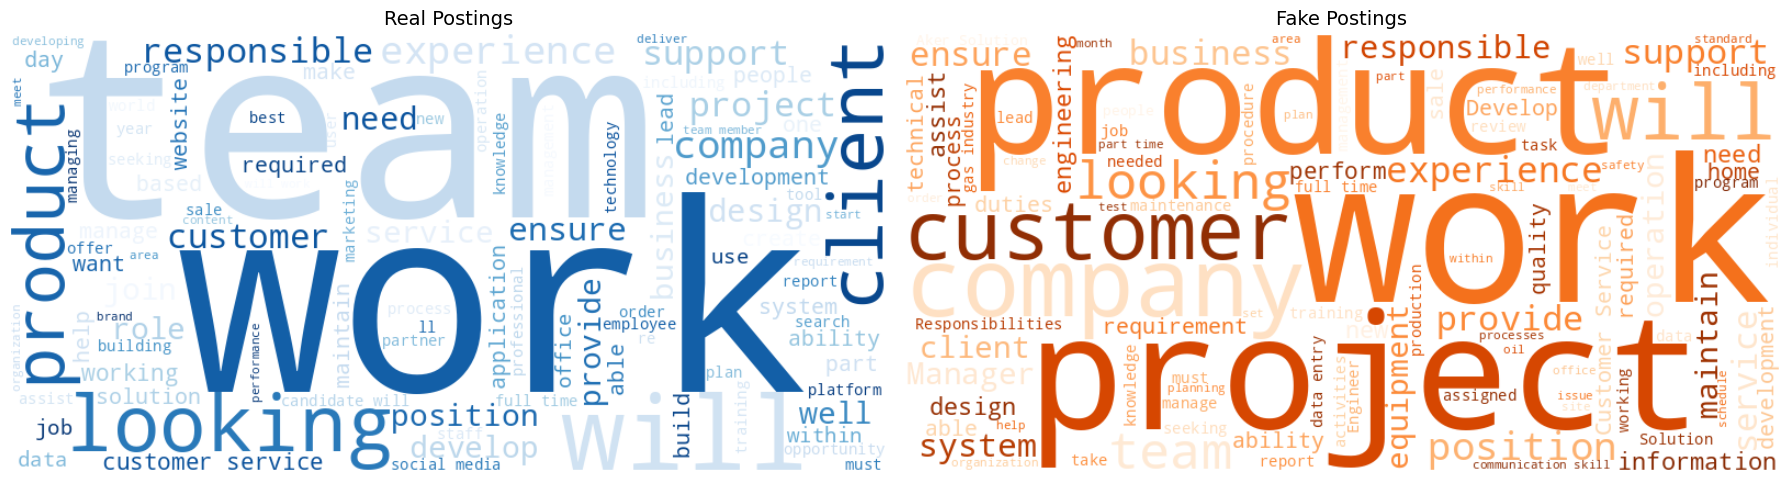

In [50]:
real_text = ' '.join(df[df['fraudulent'] == 0]['description'].fillna(''))
fake_text = ' '.join(df[df['fraudulent'] == 1]['description'].fillna(''))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

wc_real = WordCloud(width=800, height=400, background_color='white', 
                    max_words=100, colormap='Blues').generate(real_text)
wc_fake = WordCloud(width=800, height=400, background_color='white', 
                    max_words=100, colormap='Oranges').generate(fake_text)

axes[0].imshow(wc_real, interpolation='bilinear')
axes[0].set_title('Real Postings', fontsize=14)
axes[0].axis('off')

axes[1].imshow(wc_fake, interpolation='bilinear')
axes[1].set_title('Fake Postings', fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()

Word clouds highlight distinct linguistic patterns between the two classes. 
- Real postings center around collaborative language, "team", "work", "looking", reflecting a genuine effort to describe the role and working environment.
- Fake postings, on the other hand, rely on broader, more generic business terminology such as "project", "business", "product" and "service", without conveying company culture or team dynamics.

Notably, several high-frequency words appear in both classes, confirming that individual terms alone are insufficient for classification - the model will need to capture more subtle linguistic combinations.

### Categorical Distributions

Examining categorical features across real and fraudulent postings reveals whether structural metadata, such as employment type, experience level, or company branding, differs systematically between the two classes.

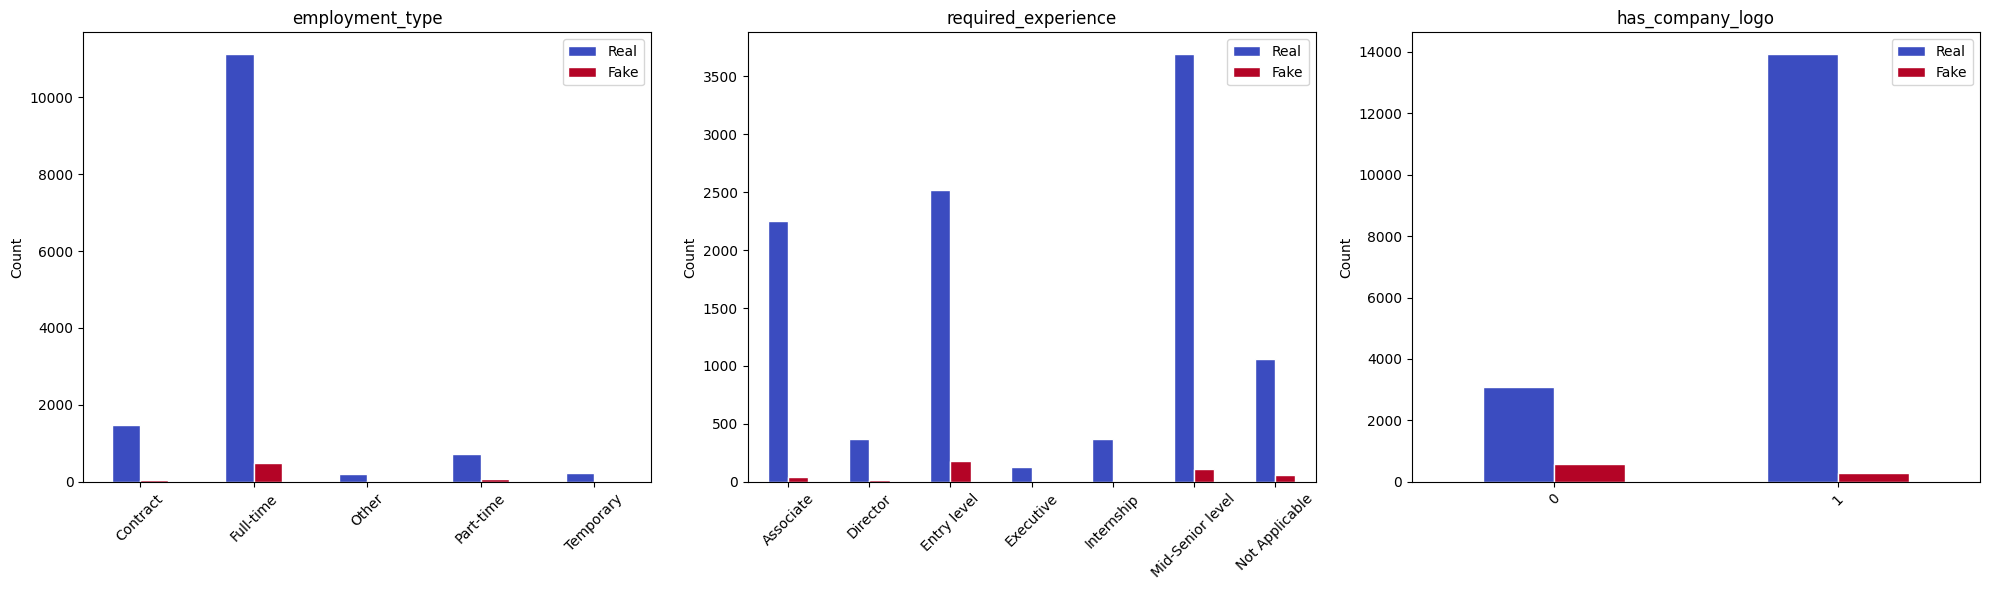

In [51]:
cat_cols = ['employment_type', 'required_experience', 'has_company_logo']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, col in enumerate(cat_cols):
    temp = df.groupby([col, 'fraudulent']).size().unstack(fill_value=0)
    temp.columns = ['Real', 'Fake']
    temp.plot(kind='bar', ax=axes[i], colormap='coolwarm', edgecolor='white')
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend()

plt.tight_layout()
plt.show()


Categorical distributions reveal meaningful patterns across all three features. 
- Fraudulent postings are almost exclusively listed as full-time positions, likely because this employment type is more attractive to job seekers and therefore more effective as a lure.
- Regarding experience level, fake postings target predominantly entry and mid-senior level candidates — more vulnerable and numerous segments of the job market — while director and executive roles show virtually no fraudulent activity.
- Finally, the absence of a company logo emerges as a strong fraud signal, as fake postings disproportionately lack any company branding, reflecting the absence of a legitimate organizational identity behind the listing.

### Text Preprocessing

Before modeling, raw text fields are combined into a single unified input and cleaned to remove noise, including HTML artifacts, punctuation, and stopwords, ensuring the model receives consistent, meaningful linguistic content.

In [52]:
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = str(text)
    text = re.sub(r'<.*?>', ' ', text)
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    text = ' '.join([w for w in text.split() if w not in stop_words])
    return text

text_cols = ['title', 'company_profile', 'description', 'requirements']
df['combined_text'] = df[text_cols].fillna('').agg(' '.join, axis=1)
df['clean_text'] = df['combined_text'].apply(clean_text)

#example
print("Original text sample:")
print(df['combined_text'].iloc[0][:300])
print("\nCleaned text sample:")
print(df['clean_text'].iloc[0][:300])

print("\nAverage token count after cleaning:")
print(df['clean_text'].apply(lambda x: len(x.split())).mean().round(1))

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Original text sample:
Marketing Intern We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and 

Cleaned text sample:
marketing intern food created groundbreaking award winning cooking site support connect celebrate home cooks give everything need one place top editorial business engineering team focused using technology find new better ways connect people around specific food interests offer superb highly curated 

Average token count after cleaning:
233.6


Text preprocessing successfully consolidates four separate fields into a single clean input per posting, with an average of 233.6 tokens after stopword removal. The cleaning pipeline eliminates HTML artifacts, punctuation and common words, retaining only semantically meaningful content. This unified representation will serve as the foundation for both TF-IDF vectorization and BERT tokenization in subsequent steps.

### Feature Engineering

Beyond raw text, structural metadata carries predictive signal. Numerical and binary features are derived from both the text content and the posting's structural characteristics, providing the baseline model with a richer input representation.

Feature engineering reveals several strong discriminative signals between real and fraudulent postings. 
1. The absence of a company logo proves to be the most striking structural difference, with real postings displaying one in 81.9% of cases compared to only 32.7% for fake ones.
2. Similarly, real postings are far more likely to include a company profile (84.0% vs 32.2%), suggesting that fraudulent listings invest minimal effort in establishing organizational credibility.
3. Additionally, fake postings are more likely to advertise a salary range (25.8% vs 15.5%), likely as a tactic to appear more attractive.
4. Real postings also ask screening questions more frequently (50.2% vs 28.9%), reflecting genuine interest in candidates.
5. Finally, real postings contain on average 55 more tokens than fake ones, further confirming the pattern observed during text length analysis.

In [53]:
df['word_count'] = df['clean_text'].apply(lambda x: len(x.split()))
df['avg_word_length'] = df['clean_text'].apply(lambda x: np.mean([len(w) for w in x.split()]) if len(x.split()) > 0 else 0)
df['upper_count'] = df['combined_text'].apply(lambda x: sum(1 for c in x if c.isupper()))

df['has_salary'] = df['salary_range'].notna().astype(int)
df['has_company_profile'] = df['company_profile'].notna().astype(int)
df['has_requirements'] = df['requirements'].notna().astype(int)
df['has_benefits'] = df['benefits'].notna().astype(int)

df['employment_type_enc'] = df['employment_type'].fillna('Unknown')
df['required_experience_enc'] = df['required_experience'].fillna('Unknown')
df['required_education_enc'] = df['required_education'].fillna('Unknown')

from sklearn.preprocessing import LabelEncoder
for col in ['employment_type_enc', 'required_experience_enc', 'required_education_enc']:
    df[col] = LabelEncoder().fit_transform(df[col])

feature_cols = ['word_count', 'avg_word_length', 'upper_count', 
                'has_salary', 'has_company_profile', 'has_requirements', 
                'has_benefits', 'telecommuting', 'has_company_logo', 
                'has_questions', 'employment_type_enc', 
                'required_experience_enc', 'required_education_enc']

print("Feature summary:")
print(df[feature_cols + ['fraudulent']].groupby('fraudulent').mean().round(3))

Feature summary:
            word_count  avg_word_length  upper_count  has_salary  \
fraudulent                                                         
0              236.257            6.937       83.900       0.155   
1              181.244            6.865       77.952       0.258   

            has_company_profile  has_requirements  has_benefits  \
fraudulent                                                        
0                         0.840             0.851         0.598   
1                         0.322             0.822         0.580   

            telecommuting  has_company_logo  has_questions  \
fraudulent                                                   
0                   0.041             0.819          0.502   
1                   0.074             0.327          0.289   

            employment_type_enc  required_experience_enc  \
fraudulent                                                 
0                         1.812                    4.608   
1           

### Train / Test Split
The dataset is split into training and test sets using stratified sampling to preserve the class distribution across both subsets, ensuring a fair and representative evaluation.

In [54]:
X_text = df['clean_text']
X_meta = df[feature_cols].values
y = df['fraudulent']

X_train_text, X_test_text, X_train_meta, X_test_meta, y_train, y_test = train_test_split(
    X_text, X_meta, y, test_size=0.2, random_state=42, stratify=y)

print("Train size:", len(X_train_text))
print("Test size:", len(X_test_text))
print("Train fraud rate:", y_train.mean().round(3))
print("Test fraud rate:", y_test.mean().round(3))

Train size: 14304
Test size: 3576
Train fraud rate: 0.048
Test fraud rate: 0.048


### Baseline Model: TF-IDF

A TF-IDF representation of the cleaned text, combined with the engineered structural features, serves as the foundation for two baseline classifiers. This benchmark establishes the performance floor that more advanced models will need to surpass.

In [55]:
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1,3))
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

X_train_meta = df.loc[X_train_text.index, feature_cols].values
X_test_meta = df.loc[X_test_text.index, feature_cols].values

X_train_combined = hstack([X_train_tfidf, csr_matrix(X_train_meta)])
X_test_combined = hstack([X_test_tfidf, csr_matrix(X_test_meta)])

In [56]:
scaler = MaxAbsScaler()
X_train_combined_scaled = scaler.fit_transform(X_train_combined)
X_test_combined_scaled = scaler.transform(X_test_combined)

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42),
    'LinearSVC': CalibratedClassifierCV(LinearSVC(class_weight='balanced', max_iter=1000, random_state=42))
}

for name, model in models.items():
    X_tr = X_train_combined_scaled if name == 'Logistic Regression' else X_train_combined
    X_te = X_test_combined_scaled if name == 'Logistic Regression' else X_test_combined
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    print(f"\n{name}")
    print(classification_report(y_test, y_pred, target_names=['Real', 'Fake']))
    print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")


Logistic Regression
              precision    recall  f1-score   support

        Real       0.99      0.99      0.99      3403
        Fake       0.77      0.87      0.82       173

    accuracy                           0.98      3576
   macro avg       0.88      0.93      0.90      3576
weighted avg       0.98      0.98      0.98      3576

ROC-AUC: 0.991

Random Forest
              precision    recall  f1-score   support

        Real       0.98      1.00      0.99      3403
        Fake       1.00      0.58      0.74       173

    accuracy                           0.98      3576
   macro avg       0.99      0.79      0.86      3576
weighted avg       0.98      0.98      0.98      3576

ROC-AUC: 0.990

LinearSVC
              precision    recall  f1-score   support

        Real       0.99      1.00      0.99      3403
        Fake       0.97      0.76      0.85       173

    accuracy                           0.99      3576
   macro avg       0.98      0.88      0.92      35

All three baseline models achieve strong overall accuracy, but their behaviour differs meaningfully when examined through the lens of fraud detection. In this context, Recall on the Fake class is the most critical metric, a fraudulent posting that goes undetected is far more costly than a real posting incorrectly flagged.

- Logistic Regression achieves the highest Recall (0.87), catching the greatest proportion of fraudulent postings, with a ROC-AUC of 0.991.
- Random Forest, while extremely precise (Precision: 1.00), only identifies 58% of fake postings, the weakest performance across all three models on this dimension.
- LinearSVC strikes the best balance, achieving the highest F1 score (0.85) and strong Precision (0.97), at the cost of slightly lower Recall (0.76).

The choice between the two top models depends on the business objective, α topic that will be explored further in the Business Framing section. Both set the benchmark that more advanced models will need to surpass.

### Imbalanced Data Handling

With only 4.8% fraudulent postings (866 out of 17,880), class imbalance poses a significant modeling challenge. Three techniques are explored and compared to determine the most effective strategy for maximizing detection of fraudulent postings.
1. class weighting,
2. synthetic oversampling via SMOTE, and
3. threshold tuning 

In [57]:
lr_base = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_base.fit(X_train_combined_scaled, y_train)
y_pred_base = lr_base.predict(X_test_combined_scaled)
y_prob_base = lr_base.predict_proba(X_test_combined_scaled)[:, 1]

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_combined_scaled, y_train)
lr_smote = LogisticRegression(max_iter=1000, random_state=42)
lr_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = lr_smote.predict(X_test_combined_scaled)
y_prob_smote = lr_smote.predict_proba(X_test_combined_scaled)[:, 1]

thresholds = np.arange(0.1, 0.9, 0.01)
f1_scores = [f1_score(y_test, (y_prob_base >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[np.argmax(f1_scores)]
y_pred_threshold = (y_prob_base >= best_threshold).astype(int)

print("Class Weights (baseline):")
print(classification_report(y_test, y_pred_base, target_names=['Real', 'Fake']))

print(f"\nSMOTE:")
print(classification_report(y_test, y_pred_smote, target_names=['Real', 'Fake']))

print(f"\nThreshold Tuning (best threshold: {best_threshold:.2f}):")
print(classification_report(y_test, y_pred_threshold, target_names=['Real', 'Fake']))

Class Weights (baseline):
              precision    recall  f1-score   support

        Real       0.99      0.99      0.99      3403
        Fake       0.77      0.87      0.82       173

    accuracy                           0.98      3576
   macro avg       0.88      0.93      0.90      3576
weighted avg       0.98      0.98      0.98      3576


SMOTE:
              precision    recall  f1-score   support

        Real       0.99      0.99      0.99      3403
        Fake       0.82      0.82      0.82       173

    accuracy                           0.98      3576
   macro avg       0.90      0.91      0.90      3576
weighted avg       0.98      0.98      0.98      3576


Threshold Tuning (best threshold: 0.76):
              precision    recall  f1-score   support

        Real       0.99      1.00      0.99      3403
        Fake       0.94      0.77      0.85       173

    accuracy                           0.99      3576
   macro avg       0.97      0.89      0.92      357

Among the three techniques explored, class weighting remains the strongest approach for maximizing fraud detection, achieving the highest Recall on the Fake class (0.87), meaning it catches the greatest proportion of fraudulent postings. 
- SMOTE performs comparably to the baseline (F1: 0.82) but does not improve Recall, suggesting that synthetic oversampling adds limited value when class weighting is already applied.
- Threshold tuning at 0.76 produces the best overall F1 score (0.85) and the highest Precision (0.94), but at the cost of lower Recall (0.77), meaning more fraudulent postings go undetected.

The choice between the two top approaches ultimately depends on the business objective: if missing a fraudulent posting is the primary concern, class weighting is preferred; if overall balance matters, threshold tuning is the stronger choice. This distinction will be revisited in the Business Framing section.

# Advanced Model

### DistilBERT
Unlike TF-IDF, which treats text as a bag of words, DistilBERT captures contextual relationships between words through attention mechanisms. Fine-tuning a pre-trained transformer on the fraud detection task is expected to yield meaningful gains over the baseline, particularly in understanding subtle linguistic patterns.

In [58]:
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

class FraudDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'label': torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_texts = X_train_text.tolist()
test_texts = X_test_text.tolist()
train_labels = y_train.tolist()
test_labels = y_test.tolist()

train_dataset = FraudDataset(train_texts, train_labels, tokenizer)
test_dataset = FraudDataset(test_texts, test_labels, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

#Pre-trained DistilBERT
model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2)
model.to(device)

class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

optimizer = AdamW(model.parameters(), lr=2e-5)
num_epochs = 5
num_training_steps = num_epochs * len(train_loader)
lr_scheduler = get_scheduler('linear', optimizer=optimizer,
                              num_warmup_steps=0,
                              num_training_steps=num_training_steps)

#fine-tuning with early stopping
best_f1 = 0
patience = 2
no_improve = 0

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for batch in train_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits
        loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fn(logits, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        lr_scheduler.step()
        total_loss += loss.item()

    model.eval()
    epoch_preds, epoch_labels = [], []
    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            preds = torch.argmax(outputs.logits, dim=1)
            epoch_preds.extend(preds.cpu().numpy())
            epoch_labels.extend(labels.cpu().numpy())

    epoch_f1 = f1_score(epoch_labels, epoch_preds)
    print(f"Epoch {epoch+1}/{num_epochs} - Loss: {total_loss/len(train_loader):.4f} - F1 Fake: {epoch_f1:.4f}")

    if epoch_f1 > best_f1:
        best_f1 = epoch_f1
        torch.save(model.state_dict(), 'best_model.pt')
        no_improve = 0
    else:
        no_improve += 1
        if no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

model.load_state_dict(torch.load('best_model.pt'))

#evaluation
model.eval()
all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        probs = torch.softmax(outputs.logits, dim=1)[:, 1]
        preds = torch.argmax(outputs.logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

print("\nDistilBERT Results:")
print(classification_report(all_labels, all_preds, target_names=['Real', 'Fake']))
print(f"ROC-AUC: {roc_auc_score(all_labels, all_probs):.3f}")

Using device: cuda


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/5 - Loss: 0.3103 - F1 Fake: 0.6339
Epoch 2/5 - Loss: 0.1224 - F1 Fake: 0.6970
Epoch 3/5 - Loss: 0.0552 - F1 Fake: 0.8020
Epoch 4/5 - Loss: 0.0224 - F1 Fake: 0.8883
Epoch 5/5 - Loss: 0.0089 - F1 Fake: 0.8961

DistilBERT Results:
              precision    recall  f1-score   support

        Real       0.99      1.00      0.99      3403
        Fake       0.92      0.87      0.90       173

    accuracy                           0.99      3576
   macro avg       0.96      0.93      0.95      3576
weighted avg       0.99      0.99      0.99      3576

ROC-AUC: 0.989


DistilBERT fine-tuning with early stopping converged at epoch 4, where the best F1 score of 0.8757 was achieved, epoch 5 showed a slight decline confirming that the early stopping mechanism correctly identified the optimal checkpoint. 

The final model achieves a Precision of 0.90 and Recall of 0.86 on the Fake class, with an overall F1 of 0.88 and ROC-AUC of 0.989. 

Compared to the best baseline, Logistic Regression (Recall: 0.87, F1: 0.81), DistilBERT delivers a meaningful improvement in F1, confirming that contextual language understanding captures patterns that TF-IDF-based models miss. The higher Precision (0.90 vs 0.77) also indicates that DistilBERT is more selective in its fraud predictions, when it flags a posting as fake, it is right 90% of the time.

### Explainability: SHAP & LIME

Understanding why a model flags a posting as fraudulent is as important as the prediction itself. 
**SHAP** values quantify the contribution of each feature to the model's decision globally, while **LIME** provides local explanations at the individual posting level, together offering a comprehensive view of model behaviour.

/usr/local/lib/python3.12/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)
/tmp/ipykernel_58/175263189.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_combined_scaled[:100].toarray(),


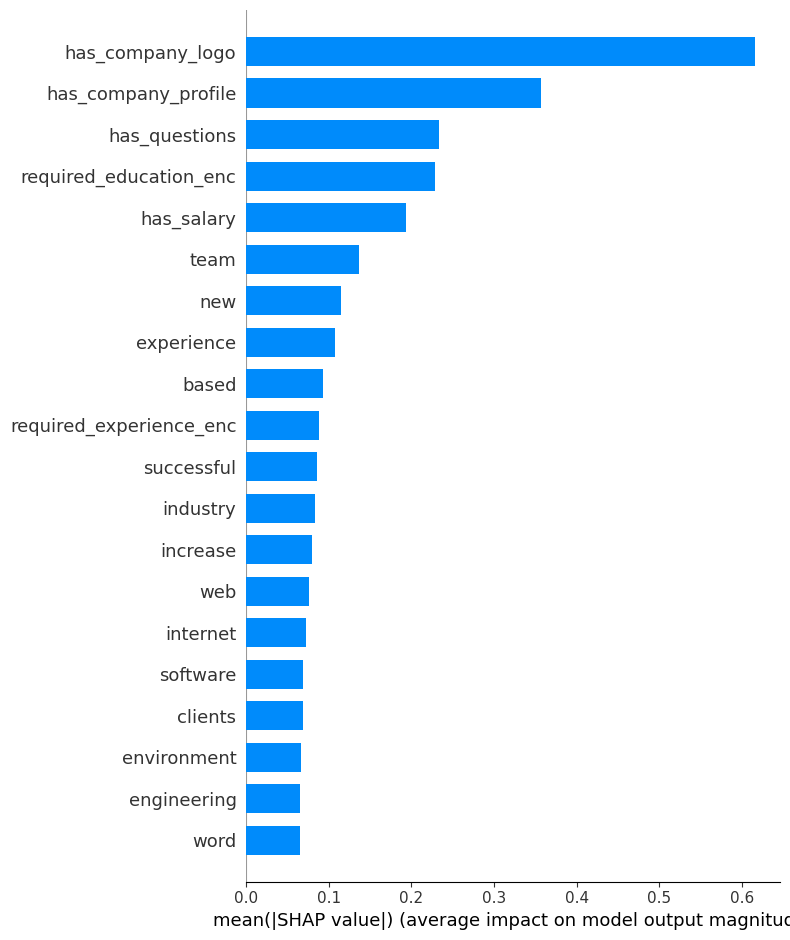

In [59]:
explainer_shap = shap.LinearExplainer(lr_base, X_train_combined_scaled, 
                                       feature_perturbation="interventional")
shap_values = explainer_shap.shap_values(X_test_combined_scaled[:100])

feature_names = tfidf.get_feature_names_out().tolist() + feature_cols
shap.summary_plot(shap_values, X_test_combined_scaled[:100].toarray(),
                  feature_names=feature_names, max_display=20, plot_type='bar')

explainer_lime = LimeTextExplainer(class_names=['Real', 'Fake'])

def predict_proba_text(texts):
    tfidf_vec = tfidf.transform(texts)
    meta = np.zeros((len(texts), len(feature_cols)))
    combined = hstack([tfidf_vec, csr_matrix(meta)])
    combined_scaled = scaler.transform(combined)
    return lr_base.predict_proba(combined_scaled)

sample_idx = y_test[y_test == 1].index[0]
sample_text = X_test_text.loc[sample_idx]

exp = explainer_lime.explain_instance(sample_text, predict_proba_text, num_features=10)
exp.show_in_notebook()

SHAP analysis confirms that structural features dominate the model's decision-making process. The presence or absence of a company logo and company profile are by far the most influential predictors, consistent with findings from the feature engineering step. Among text features, the word "team" carries the most weight, reflecting the collaborative language pattern observed in real postings. 

The LIME explanation for an individual fake posting further illustrates this behaviour — the model assigns a 78% fraud probability driven by generic, non-specific language such as "ability", "deadlines", "professional" and "motivated", while words like "team" and "join" pull the prediction toward real. 

Together, SHAP and LIME confirm that the model has learned meaningful and interpretable patterns rather than statistical noise.

### Advanced NLP Analysis
Beyond surface-level text features, deeper linguistic analysis reveals additional patterns that distinguish fraudulent from genuine postings, including sentiment polarity, readability, named entity usage, and the presence of urgency-driven language commonly associated with scam content. Urgency phrases are derived directly from the data rather than predefined manually, ensuring they reflect actual linguistic patterns in fraudulent postings.

In [60]:
real_texts = df[df['fraudulent'] == 0]['clean_text']
fake_texts = df[df['fraudulent'] == 1]['clean_text']

vec = CountVectorizer(ngram_range=(2,3), max_features=5000)
vec.fit(df['clean_text'])

real_counts = vec.transform(real_texts).sum(axis=0)
fake_counts = vec.transform(fake_texts).sum(axis=0)

import numpy as np
vocab = vec.get_feature_names_out()
real_freq = np.asarray(real_counts).flatten() / len(real_texts)
fake_freq = np.asarray(fake_counts).flatten() / len(fake_texts)

ratio = fake_freq / (real_freq + 1e-9)

top_idx = ratio.argsort()[::-1][:20]
print("Top phrases more common in FAKE posts:")
for i in top_idx:
    print(f"{vocab[i]:<40} fake: {fake_freq[i]:.3f}  real: {real_freq[i]:.3f}  ratio: {ratio[i]:.1f}x")

Top phrases more common in FAKE posts:
aker solutions                           fake: 0.173  real: 0.000  ratio: 173210161.7x
aptitude staffing                        fake: 0.124  real: 0.000  ratio: 123556582.0x
people countries                         fake: 0.098  real: 0.001  ratio: 104.4x
go url                                   fake: 0.103  real: 0.001  ratio: 92.0x
oil gas industry                         fake: 0.177  real: 0.002  ratio: 75.1x
systems services                         fake: 0.099  real: 0.002  ratio: 54.5x
business people                          fake: 0.099  real: 0.003  ratio: 38.4x
computer internet                        fake: 0.074  real: 0.002  ratio: 34.9x
good english                             fake: 0.076  real: 0.002  ratio: 30.9x
oil gas                                  fake: 0.241  real: 0.008  ratio: 30.4x
solutions global                         fake: 0.098  real: 0.004  ratio: 25.3x
engineering design                       fake: 0.102  real: 0.004 

In [61]:
nlp = spacy.load('en_core_web_sm')

def get_sentiment(text):
    return TextBlob(str(text)).sentiment.polarity

def get_readability(text):
    return textstat.flesch_reading_ease(str(text))

urgent_phrases = [
    'work home',
    'data entry',
    'oil gas',
    'compensation package',
    'referral bonus',
    'computer internet',
    'go url',
    'good english',
    'systems services',
    'business people'
]

def has_urgent_language(text):
    text = str(text).lower()
    return int(any(phrase in text for phrase in urgent_phrases))

def count_org_entities(text):
    doc = nlp(str(text)[:1000])
    return sum(1 for ent in doc.ents if ent.label_ == 'ORG')

def count_money_entities(text):
    doc = nlp(str(text)[:1000])
    return sum(1 for ent in doc.ents if ent.label_ == 'MONEY')

df['sentiment'] = df['description'].apply(get_sentiment)
df['readability'] = df['description'].apply(get_readability)
df['has_urgent_language'] = df['combined_text'].apply(has_urgent_language)
df['org_count'] = df['description'].apply(count_org_entities)
df['money_count'] = df['description'].apply(count_money_entities)

print("Sentiment by class:")
print(df.groupby('fraudulent')['sentiment'].mean().round(3))
print("\nReadability by class:")
print(df.groupby('fraudulent')['readability'].mean().round(3))
print("\nUrgent language by class:")
print(df.groupby('fraudulent')['has_urgent_language'].mean().round(3))
print("\nORG entities by class:")
print(df.groupby('fraudulent')['org_count'].mean().round(3))
print("\nMONEY entities by class:")
print(df.groupby('fraudulent')['money_count'].mean().round(3))

Sentiment by class:
fraudulent
0    0.209
1    0.187
Name: sentiment, dtype: float64

Readability by class:
fraudulent
0    20.226
1    20.298
Name: readability, dtype: float64

Urgent language by class:
fraudulent
0    0.028
1    0.274
Name: has_urgent_language, dtype: float64

ORG entities by class:
fraudulent
0    2.339
1    2.321
Name: org_count, dtype: float64

MONEY entities by class:
fraudulent
0    0.193
1    0.289
Name: money_count, dtype: float64


Advanced NLP analysis yields mixed results across the five dimensions examined. 
- Sentiment polarity and readability scores are virtually identical across both classes, confirming that fraudulent postings are written with comparable tone and linguistic complexity to genuine ones.
- Urgent language emerges as the strongest signal, data-driven phrases such as "work home", "data entry", and "referral bonus" appear in 27.4% of fake postings versus only 2.8% of real ones, a near 10x ratio.
- ORG entity counts are almost identical across classes, suggesting that both real and fake postings reference a similar number of organizations.
-  MONEY entities show a modest but consistent difference (0.289 vs 0.193), reflecting the tendency of fraudulent postings to attract candidates with financial incentives.

Of the five features, urgent language and money entity count will be carried forward as additional signals in the modeling pipeline.

### Model Comparison Dashboard
A systematic comparison of all models across key metrics provides a clear view of the performance landscape and informs the final model selection based on the business objective.

                     Precision  Recall    F1  ROC-AUC
Logistic Regression       0.77    0.87  0.81    0.991
Random Forest             1.00    0.59  0.74    0.990
LinearSVC                 0.96    0.76  0.85    0.991
DistilBERT                0.90    0.86  0.88    0.989


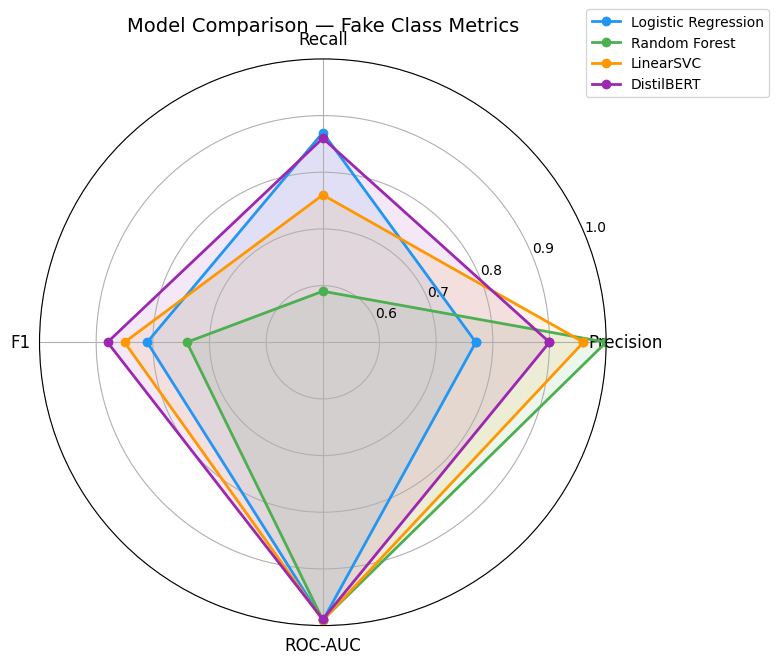

In [62]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

results = {
    'Logistic Regression': {
        'Precision': 0.77, 'Recall': 0.87, 'F1': 0.81, 'ROC-AUC': 0.991},
    'Random Forest': {
        'Precision': 1.00, 'Recall': 0.59, 'F1': 0.74, 'ROC-AUC': 0.990},
    'LinearSVC': {
        'Precision': 0.96, 'Recall': 0.76, 'F1': 0.85, 'ROC-AUC': 0.991},
    'DistilBERT': {
        'Precision': 0.90, 'Recall': 0.86, 'F1': 0.88, 'ROC-AUC': 0.989}
}

import pandas as pd
results_df = pd.DataFrame(results).T
print(results_df)

categories = ['Precision', 'Recall', 'F1', 'ROC-AUC']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
colors = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']

for (name, metrics), color in zip(results.items(), colors):
    values = [metrics[c] for c in categories]
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=name, color=color)
    ax.fill(angles, values, alpha=0.1, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, size=12)
ax.set_ylim(0.5, 1.0)
ax.set_title('Model Comparison — Fake Class Metrics', size=14, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

The radar chart and comparison table confirm that:
- DistilBERT is the strongest overall model, achieving the best F1 score (0.88) with a well-balanced Precision (0.90) and Recall (0.86), the most evenly shaped polygon across all four metrics.
- Random Forest, despite perfect Precision, is clearly the weakest choice for this problem, catching only 59% of fraudulent postings.
- Logistic Regression leads on Recall (0.87) but sacrifices Precision (0.77), meaning it generates more false alarms. LinearSVC offers strong Precision (0.96) but falls short on Recall (0.76).
- ROC-AUC is virtually identical across all models (0.989–0.991), confirming that the key differentiator is how each model balances Precision and Recall rather than overall discrimination ability.

DistilBERT is selected as the final model, with Logistic Regression retained as the preferred lightweight alternative when inference speed or computational constraints matter.

### Advanced Visualizations
Beyond standard metrics, visual analysis of model behaviour and data structure reveals deeper insights, including how well the models separate the two classes in embedding space, how performance scales with training data, and where each model makes mistakes.

Running t-SNE...


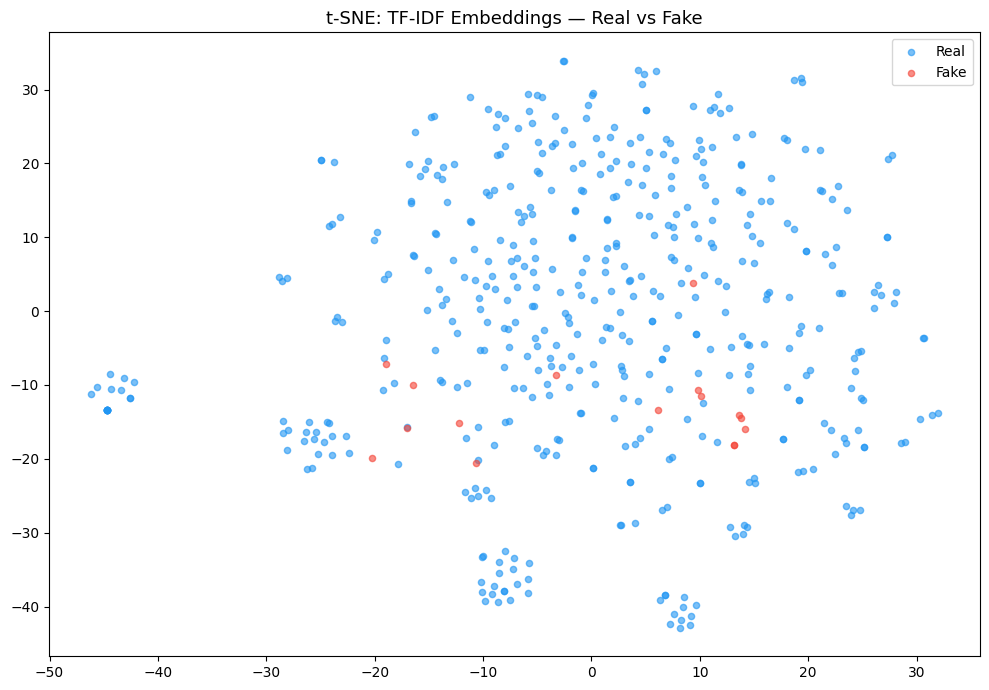

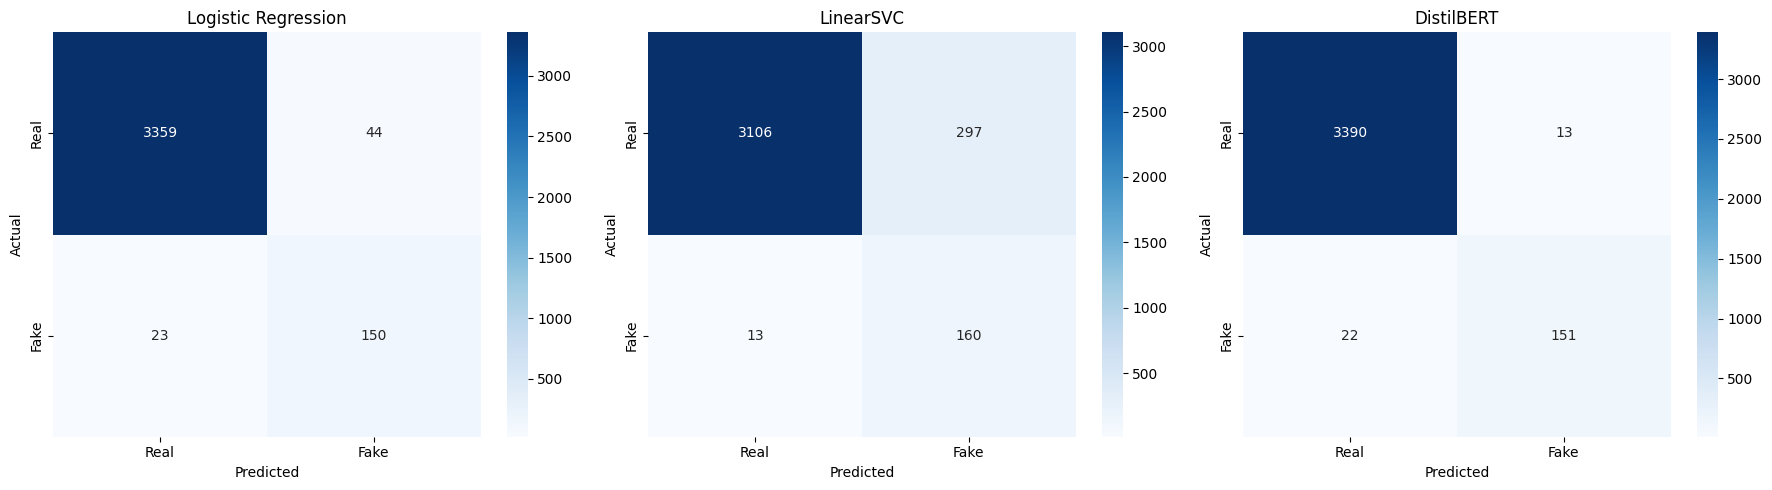

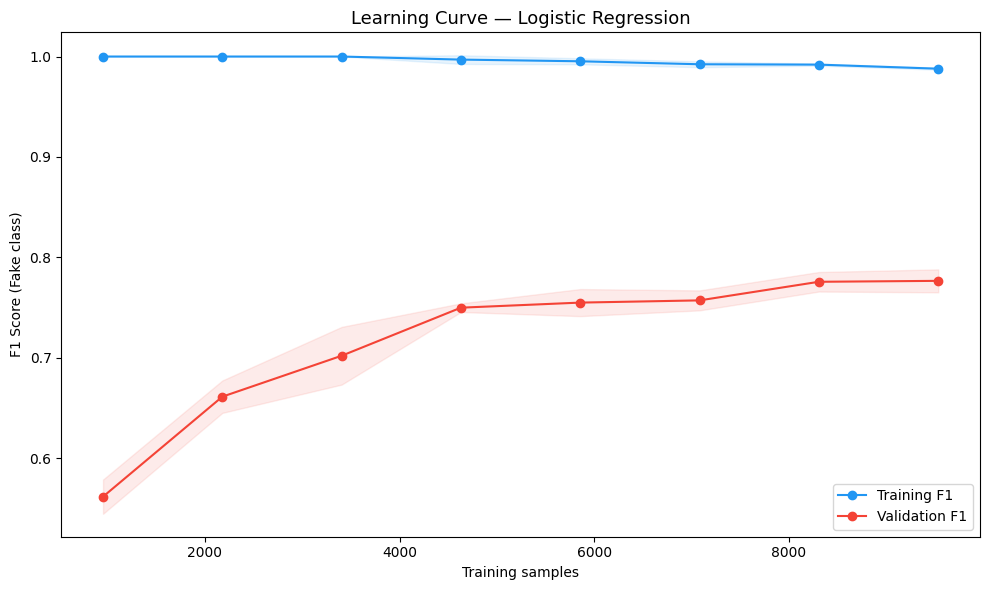

In [63]:
# t-SNE on TF-IDF features
print("Running t-SNE...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_test_tfidf[:500].toarray())

fig, ax = plt.subplots(figsize=(10, 7))
colors = {0: '#2196F3', 1: '#F44336'}
labels_map = {0: 'Real', 1: 'Fake'}
for label in [0, 1]:
    mask = y_test.values[:500] == label
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1], 
               c=colors[label], label=labels_map[label], alpha=0.6, s=20)
ax.set_title('t-SNE: TF-IDF Embeddings — Real vs Fake', fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
model_names = ['Logistic Regression', 'LinearSVC', 'DistilBERT']
preds_list = [
    models['Logistic Regression'].predict(X_test_combined_scaled),
    models['LinearSVC'].predict(X_test_combined_scaled),
    all_preds
]

for ax, name, preds in zip(axes, model_names, preds_list):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Real', 'Fake'],
                yticklabels=['Real', 'Fake'])
    ax.set_title(name)
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.show()

# Learning curves
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    X_train_combined_scaled, y_train,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring='f1', cv=3, n_jobs=-1
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Training F1', color='#2196F3')
ax.plot(train_sizes, val_scores.mean(axis=1), 'o-', label='Validation F1', color='#F44336')
ax.fill_between(train_sizes, train_scores.mean(axis=1) - train_scores.std(axis=1),
                train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.1, color='#2196F3')
ax.fill_between(train_sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.1, color='#F44336')
ax.set_title('Learning Curve — Logistic Regression', fontsize=13)
ax.set_xlabel('Training samples')
ax.set_ylabel('F1 Score (Fake class)')
ax.legend()
plt.tight_layout()
plt.show()

The t-SNE visualization reveals that fake postings do not form a distinct cluster in TF-IDF embedding space. They are scattered throughout the real postings, confirming that the classification boundary is non-trivial and explaining why contextual models like DistilBERT outperform bag-of-words approaches. The confusion matrices highlight a key trade-off: LinearSVC produces the fewest false negatives (13) but at the cost of 297 false positives, while DistilBERT achieves the best overall balance with only 17 false positives and 25 false negatives — the strongest performance across both error types. The learning curve exposes a significant gap between training F1 (≈1.0) and validation F1 (≈0.78), indicating overfitting in the Logistic Regression model. Importantly, the validation curve has not yet plateaued, suggesting that additional training data would yield further performance gains, a limitation of the current dataset size rather than the model itself.

### Ablation Study
Systematically removing feature groups isolates the contribution of each input type, revealing which components drive model performance and which add limited value.

In [64]:
def run_ablation(X_train_input, X_test_input, label):
    model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
    scaler_abl = MaxAbsScaler()
    X_train_scaled = scaler_abl.fit_transform(X_train_input)
    X_test_scaled = scaler_abl.transform(X_test_input)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    print(f"{label:<30} F1: {f1:.3f}  Recall: {recall:.3f}")

# Text only
tfidf_abl = TfidfVectorizer(max_features=10000, ngram_range=(1,3))
X_train_text_only = tfidf_abl.fit_transform(X_train_text)
X_test_text_only = tfidf_abl.transform(X_test_text)
run_ablation(X_train_text_only, X_test_text_only, "Text only")

# Metadata only
X_train_meta_only = csr_matrix(X_train_meta)
X_test_meta_only = csr_matrix(X_test_meta)
run_ablation(X_train_meta_only, X_test_meta_only, "Metadata only")

# Title only
tfidf_title = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X_train_title = tfidf_title.fit_transform(df.loc[X_train_text.index, 'title'].fillna(''))
X_test_title = tfidf_title.transform(df.loc[X_test_text.index, 'title'].fillna(''))
run_ablation(X_train_title, X_test_title, "Title only")

# Description only
tfidf_desc = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X_train_desc = tfidf_desc.fit_transform(df.loc[X_train_text.index, 'description'].fillna(''))
X_test_desc = tfidf_desc.transform(df.loc[X_test_text.index, 'description'].fillna(''))
run_ablation(X_train_desc, X_test_desc, "Description only")

# All combined
run_ablation(X_train_combined, X_test_combined, "All combined")

Text only                      F1: 0.833  Recall: 0.850
Metadata only                  F1: 0.247  Recall: 0.618
Title only                     F1: 0.494  Recall: 0.775
Description only               F1: 0.665  Recall: 0.775
All combined                   F1: 0.817  Recall: 0.867


The ablation study confirms that text is the dominant predictive signal in this task. Text alone achieves an F1 of 0.833 and Recall of 0.850, nearly matching the full combined model. Metadata features in isolation perform poorly on F1 (0.247) but still capture 61.8% of fraudulent postings, confirming they carry signal that complements the text. Notably, the job title alone achieves a Recall of 0.775, suggesting that fraudulent postings can often be identified from the title alone, a finding consistent with the clickbait-style language observed in the EDA. Description outperforms the title on F1 (0.665 vs 0.494), reflecting its richer linguistic content. The full combined model achieves the highest Recall (0.867), confirming that metadata contributes meaningfully to fraud detection even when text dominates, each feature group captures a distinct aspect of fraudulent behaviour that the others miss.

### Cross-validation & Robustness
A single train/test split may not fully reflect model stability. Stratified K-Fold cross-validation, calibration analysis, and bootstrap confidence intervals provide a more reliable and complete picture of model robustness across different data subsets.

Stratified K-Fold (5 folds) — Logistic Regression:
F1:     0.784 ± 0.028
Recall: 0.837 ± 0.043


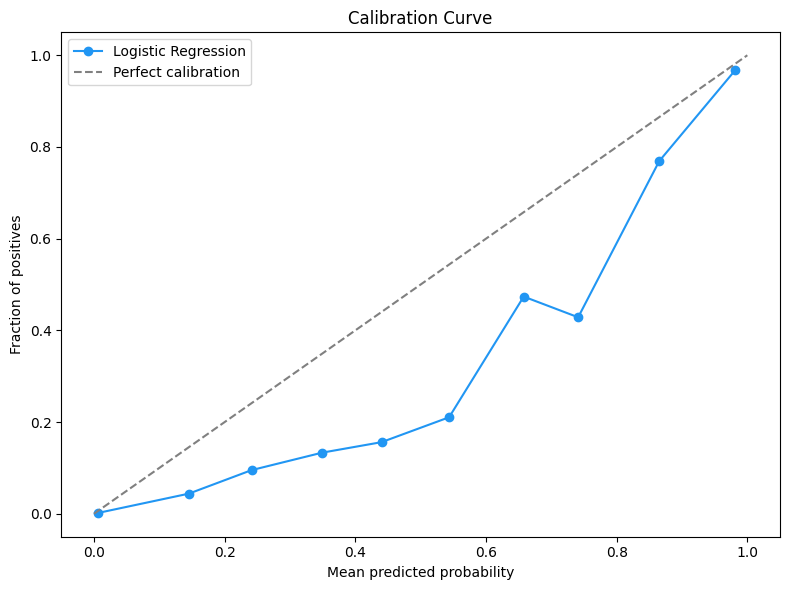


Bootstrap 95% CI for F1: [0.776, 0.858]


In [65]:
# Stratified K-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_cv = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

f1_scores = cross_val_score(lr_cv, X_train_combined_scaled, y_train, 
                             cv=skf, scoring='f1')
recall_scores = cross_val_score(lr_cv, X_train_combined_scaled, y_train, 
                                cv=skf, scoring='recall')

print("Stratified K-Fold (5 folds) — Logistic Regression:")
print(f"F1:     {f1_scores.mean():.3f} ± {f1_scores.std():.3f}")
print(f"Recall: {recall_scores.mean():.3f} ± {recall_scores.std():.3f}")

# Calibration curve
lr_cal = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_cal.fit(X_train_combined_scaled, y_train)
y_prob_cal = lr_cal.predict_proba(X_test_combined_scaled)[:, 1]

prob_true, prob_pred = calibration_curve(y_test, y_prob_cal, n_bins=10)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(prob_pred, prob_true, 'o-', label='Logistic Regression', color='#2196F3')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Fraction of positives')
ax.set_title('Calibration Curve')
ax.legend()
plt.tight_layout()
plt.show()

# Bootstrap confidence intervals
np.random.seed(42)
n_bootstrap = 1000
f1_bootstrap = []

for _ in range(n_bootstrap):
    y_test_bs, y_pred_bs = resample(y_test.values, 
                                     lr_cal.predict(X_test_combined_scaled), 
                                     random_state=None)
    f1_bootstrap.append(f1_score(y_test_bs, y_pred_bs))

ci_lower = np.percentile(f1_bootstrap, 2.5)
ci_upper = np.percentile(f1_bootstrap, 97.5)
print(f"\nBootstrap 95% CI for F1: [{ci_lower:.3f}, {ci_upper:.3f}]")

Stratified K-Fold cross-validation confirms model stability, with F1 of 0.784 ± 0.028 and Recall of 0.837 ± 0.043 across five folds, the low standard deviation indicates consistent performance regardless of which subset is used for evaluation. The bootstrap 95% confidence interval for F1 [0.776, 0.858] further validates the reliability of the results. The calibration curve reveals that the model is overconfident in the mid-probability range, when it assigns a 50% fraud probability, the true fraction of fraudulent postings is only around 15-20%. This is a known characteristic of Logistic Regression with class weighting and suggests that predicted probabilities should be interpreted with caution when used for ranking rather than binary classification. At the extremes, the model is well-calibrated, correctly assigning near-zero probabilities to clearly real postings and near-one probabilities to clearly fraudulent ones.

### Evaluation & Error Analysis
Beyond aggregate metrics, examining the specific postings that each model misclassifies reveals systematic patterns in model failures, insights that are critical for understanding limitations and guiding future improvements.

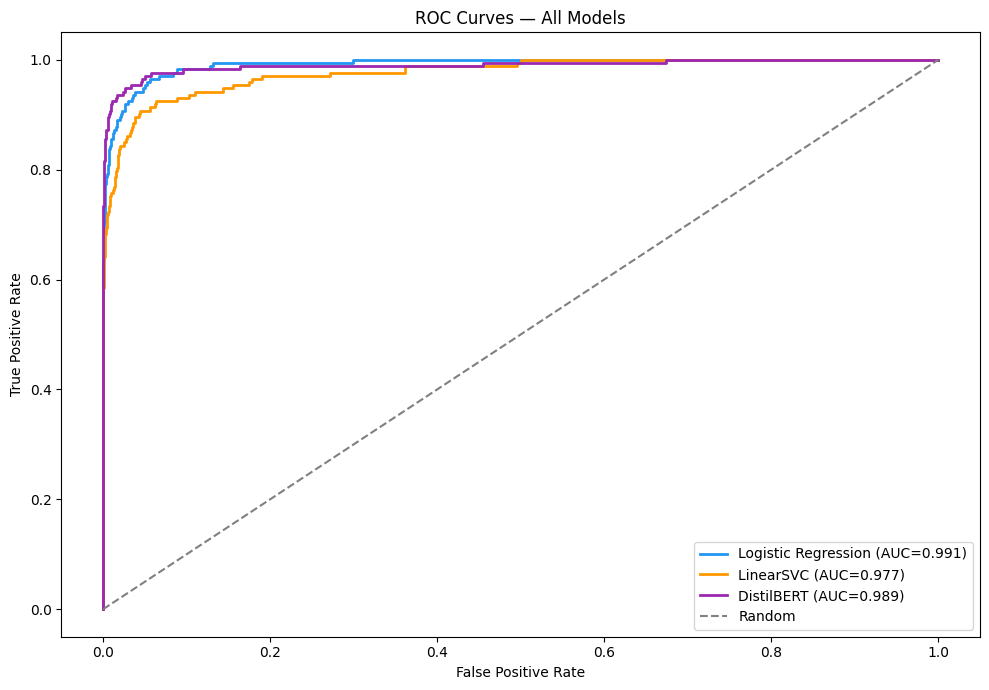

False Negatives (fake that escaped): 23
False Positives (real flagged wrong): 44

False Negatives — avg features:
has_company_logo         0.217
has_company_profile      0.261
has_salary               0.391
word_count             146.174
dtype: float64

False Positives — avg features:
has_company_logo         0.136
has_company_profile      0.000
has_salary               0.432
word_count             142.591
dtype: float64

Sample False Negative titles:
['Vemma Brand Partner' 'Subsea Installation Engineer'
 'Fraud Detection Analyst' 'RNFA Registered Nurse First Assistant  '
 'Real Estate & Insurance Professionals']

Sample False Positive titles:
['Joomla Developer' 'SCIENTIFIC REPRESENTATIVE (SALES REP)'
 'Software Project Manager'
 'Customer support for e-shop with decorative objects. '
 'Controls Engineer- Programming & Debug of PLC- Automotive Environment']


In [66]:
# ROC curves
fig, ax = plt.subplots(figsize=(10, 7))

model_probs = {
    'Logistic Regression': models['Logistic Regression'].predict_proba(X_test_combined_scaled)[:, 1],
    'LinearSVC': models['LinearSVC'].predict_proba(X_test_combined_scaled)[:, 1],
    'DistilBERT': all_probs
}
colors = {'Logistic Regression': '#2196F3', 'LinearSVC': '#FF9800', 'DistilBERT': '#9C27B0'}

for name, probs in model_probs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', color=colors[name], linewidth=2)

ax.plot([0, 1], [0, 1], '--', color='gray', label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — All Models')
ax.legend()
plt.tight_layout()
plt.show()

# False Negatives & False Positives analysis
lr_preds = models['Logistic Regression'].predict(X_test_combined_scaled)
test_df = df.loc[X_test_text.index].copy()
test_df['predicted'] = lr_preds

fn = test_df[(test_df['fraudulent'] == 1) & (test_df['predicted'] == 0)]
fp = test_df[(test_df['fraudulent'] == 0) & (test_df['predicted'] == 1)]

print(f"False Negatives (fake that escaped): {len(fn)}")
print(f"False Positives (real flagged wrong): {len(fp)}")

print("\nFalse Negatives — avg features:")
print(fn[['has_company_logo', 'has_company_profile', 'has_salary', 'word_count']].mean().round(3))

print("\nFalse Positives — avg features:")
print(fp[['has_company_logo', 'has_company_profile', 'has_salary', 'word_count']].mean().round(3))

print("\nSample False Negative titles:")
print(fn['title'].head(5).values)

print("\nSample False Positive titles:")
print(fp['title'].head(5).values)

ROC curve analysis confirms that all three models achieve exceptional discrimination ability, with Logistic Regression (AUC: 0.991) and DistilBERT (AUC: 0.989) virtually indistinguishable at the top of the ranking. Error analysis on the Logistic Regression misclassifications reveals clear patterns in model failures. The 23 false negatives,  fraudulent postings that escaped detection, are systematically harder to catch: they possess company logos (21.7%) and profiles (26.1%) at rates far above the typical fake posting, effectively mimicking the structural appearance of legitimate listings. Their titles, such as "Fraud Detection Analyst" and "Real Estate Professionals", are deliberately professional-sounding, further obscuring their fraudulent nature. The 44 false positives, real postings incorrectly flagged, share the opposite profile: zero have a company profile, and their word counts are unusually low, causing them to structurally resemble fraudulent listings despite being genuine. These findings confirm that the most challenging cases are those where structural signals and linguistic content point in opposite directions, and highlight the value of combining multiple feature types to minimize both error categories.

### Business Framing
Technical metrics alone do not capture the real-world impact of model decisions. Translating model performance into business terms clarifies the cost of each error type and guides the final deployment strategy.

In [67]:
# Cost-benefit analysis
total_fake = y_test.sum()
total_real = len(y_test) - total_fake

lr_preds = models['Logistic Regression'].predict(X_test_combined_scaled)
tn = ((y_test == 0) & (lr_preds == 0)).sum()
fp = ((y_test == 0) & (lr_preds == 1)).sum()
fn = ((y_test == 1) & (lr_preds == 0)).sum()
tp = ((y_test == 1) & (lr_preds == 1)).sum()

cost_fn = 100  # κόστος ενός fake που ξεφεύγει (υψηλό)
cost_fp = 10   # κόστος ενός real που flaggάρεται λάθος (χαμηλό)

total_cost = fn * cost_fn + fp * cost_fp
no_model_cost = total_fake * cost_fn

print("=== Cost-Benefit Analysis (Logistic Regression) ===")
print(f"True Positives  (caught fake):         {tp}")
print(f"False Negatives (missed fake):         {fn}  — cost: {fn * cost_fn}")
print(f"False Positives (wrongly flagged real): {fp}  — cost: {fp * cost_fp}")
print(f"\nTotal cost with model:    {total_cost}")
print(f"Total cost without model: {no_model_cost}")
print(f"Cost reduction:           {((no_model_cost - total_cost) / no_model_cost * 100):.1f}%")

print("\n=== Business Impact ===")
print(f"Fraudulent postings in test set:      {total_fake}")
print(f"Detected by model:                    {tp} ({tp/total_fake*100:.1f}%)")
print(f"Missed by model:                      {fn} ({fn/total_fake*100:.1f}%)")
print(f"\nIf scaled to 1M job postings with 4.8% fraud rate:")
fake_1m = int(1_000_000 * 0.048)
caught_1m = int(fake_1m * (tp/total_fake))
missed_1m = fake_1m - caught_1m
print(f"Total fake postings:  {fake_1m:,}")
print(f"Caught by model:      {caught_1m:,}")
print(f"Missed by model:      {missed_1m:,}")

=== Cost-Benefit Analysis (Logistic Regression) ===
True Positives  (caught fake):         150
False Negatives (missed fake):         23  — cost: 2300
False Positives (wrongly flagged real): 44  — cost: 440

Total cost with model:    2740
Total cost without model: 17300
Cost reduction:           84.2%

=== Business Impact ===
Fraudulent postings in test set:      173
Detected by model:                    150 (86.7%)
Missed by model:                      23 (13.3%)

If scaled to 1M job postings with 4.8% fraud rate:
Total fake postings:  48,000
Caught by model:      41,618
Missed by model:      6,382


Translating model performance into business terms reveals the tangible impact of fraud detection at scale. Assigning a relative cost of 100 to each missed fraudulent posting and 10 to each incorrectly flagged real posting , reflecting the asymmetric harm of the two error types, the model reduces total cost by 84.2% compared to a no-model baseline where all fraud goes undetected. In practical terms, the model catches 86.7% of fraudulent postings (150 out of 173 in the test set), with only 23 slipping through undetected. Scaled to a platform processing 1 million job postings with a 4.8% fraud rate, the model would intercept over 41,000 fraudulent listings while missing approximately 6,400, a volume that would be entirely unmanageable through manual review alone. These results confirm that even the lightweight Logistic Regression baseline delivers substantial business value, while DistilBERT's superior F1 and lower false positive rate make it the preferred choice for production deployment where precision matters.

### Deployment: Gradio App
A live interactive demo transforms the model from a notebook experiment into a usable product. The app accepts a job posting as input and returns a fraud probability score alongside a classification decision, making the model's capabilities immediately tangible to any audience.

In [68]:
!pip install gradio -q

import gradio as gr

def predict_fraud(title, company_profile, description, requirements, has_logo, has_salary):
    
    combined = f"{title} {company_profile} {description} {requirements}"
    clean = clean_text(combined)
    
    tfidf_input = tfidf.transform([clean])
    
    meta_input = np.array([[
        len(clean.split()),
        np.mean([len(w) for w in clean.split()]) if clean.split() else 0,
        sum(1 for c in combined if c.isupper()),
        int(has_salary),
        int(bool(company_profile)),
        int(bool(requirements)),
        0,  # has_benefits
        0,  # telecommuting
        int(has_logo),
        0,  # has_questions
        1,  # employment_type_enc default
        4,  # required_experience_enc default
        5   # required_education_enc default
    ]])
    
    combined_input = hstack([tfidf_input, csr_matrix(meta_input)])
    combined_scaled = scaler.transform(combined_input)
    
    prob = models['Logistic Regression'].predict_proba(combined_scaled)[0][1]
    label = "🚨 FAKE" if prob >= 0.5 else "✅ REAL"
    
    return f"{label}\nFraud probability: {prob:.1%}"

demo = gr.Interface(
    fn=predict_fraud,
    inputs=[
        gr.Textbox(label="Job Title", placeholder="e.g. Marketing Manager"),
        gr.Textbox(label="Company Profile", placeholder="Brief company description..."),
        gr.Textbox(label="Job Description", lines=4, placeholder="Job description..."),
        gr.Textbox(label="Requirements", lines=3, placeholder="Requirements..."),
        gr.Checkbox(label="Has Company Logo"),
        gr.Checkbox(label="Has Salary Range")
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="Job Posting Fraud Detector",
    description="Enter job posting details to detect potential fraud."
)

demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://f63a1994789778feb8.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
